# Detección de Anomalías en Piezas Industriales
## Clasificación Binaria con Transfer Learning (ResNet-50)

Este notebook implementa una solución de Deep Learning para la detección de defectos en piezas industriales.

## 1. Imports y Configuración

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import random
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision import models
from sklearn.metrics import confusion_matrix, classification_report, f1_score, recall_score, precision_score
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

EXAMPLES_PATH = "examples"
EVALUATION_PATH = "evaluation"
os.makedirs(EXAMPLES_PATH, exist_ok=True)
os.makedirs(EVALUATION_PATH, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")

Dispositivo: cuda


## 2. Generación de Dataset Sintético de Imágenes Industriales

In [6]:
def create_base_image(size=224):
    """Crea una imagen base de una pieza industrial"""
    img = Image.new('RGB', (size, size), color=(200, 200, 200))
    draw = ImageDraw.Draw(img)
    
    shape_type = random.choice(['circle', 'rectangle', 'hexagon'])
    center = size // 2
    radius = size // 4
    
    if shape_type == 'circle':
        draw.ellipse([center-radius, center-radius, center+radius, center+radius], 
                     fill=(180, 180, 190), outline=(100, 100, 100), width=3)
    elif shape_type == 'rectangle':
        draw.rectangle([center-radius, center-radius*2, center+radius, center+radius*2], 
                       fill=(180, 180, 190), outline=(100, 100, 100), width=3)
    else:
        points = []
        for i in range(6):
            angle = i * 60 * np.pi / 180
            x = center + radius * np.cos(angle)
            y = center + radius * np.sin(angle)
            points.append((x, y))
        draw.polygon(points, fill=(180, 180, 190), outline=(100, 100, 100))
    
    for _ in range(random.randint(3, 8)):
        x = random.randint(size//4, 3*size//4)
        y = random.randint(size//4, 3*size//4)
        r = random.randint(5, 15)
        draw.ellipse([x-r, y-r, x+r, y+r], fill=(160, 160, 170))
    
    return img, shape_type

def add_defects(img, defect_type=None):
    """Añade defectos a la imagen para crear ejemplos defectuosos"""
    img = img.copy()
    draw = ImageDraw.Draw(img)
    size = img.size[0]
    
    if defect_type is None:
        defect_type = random.choice(['crack', 'hole', 'deformation', 'scratch', 'stain'])
    
    if defect_type == 'crack':
        for _ in range(random.randint(3, 7)):
            x1 = random.randint(size//4, 3*size//4)
            y1 = random.randint(size//4, 3*size//4)
            x2 = x1 + random.randint(-30, 30)
            y2 = y1 + random.randint(-30, 30)
            draw.line([x1, y1, x2, y2], fill=(50, 50, 50), width=random.randint(2, 4))
    
    elif defect_type == 'hole':
        x = random.randint(size//3, 2*size//3)
        y = random.randint(size//3, 2*size//3)
        r = random.randint(10, 25)
        draw.ellipse([x-r, y-r, x+r, y+r], fill=(30, 30, 30))
    
    elif defect_type == 'deformation':
        for _ in range(random.randint(2, 5)):
            x = random.randint(size//4, 3*size//4)
            y = random.randint(size//4, 3*size//4)
            r = random.randint(15, 30)
            draw.ellipse([x-r, y-r, x+r, y+r], fill=(210, 200, 180))
    
    elif defect_type == 'scratch':
        for _ in range(random.randint(1, 3)):
            x1 = random.randint(size//4, 3*size//4)
            y1 = random.randint(size//4, 3*size//4)
            x2 = x1 + random.randint(-40, 40)
            y2 = y1 + random.randint(-40, 40)
            draw.line([x1, y1, x2, y2], fill=(120, 120, 120), width=1)
    
    else:
        x = random.randint(size//3, 2*size//3)
        y = random.randint(size//3, 2*size//3)
        r = random.randint(15, 30)
        draw.ellipse([x-r, y-r, x+r, y+r], fill=(140, 120, 100))
    
    return img

def apply_augmentation(img, brightness=0, rotation=0, noise=False):
    """Aplica transformaciones adicionales a la imagen"""
    if brightness != 0:
        from PIL import ImageEnhance
        enhancer = ImageEnhance.Brightness(img)
        img = enhancer.enhance(1 + brightness)
    
    if rotation != 0:
        img = img.rotate(rotation)
    
    if noise and random.random() > 0.5:
        img_array = np.array(img)
        noise = np.random.normal(0, 10, img_array.shape)
        img_array = np.clip(img_array + noise, 0, 255).astype(np.uint8)
        img = Image.fromarray(img_array)
    
    return img

def generate_synthetic_dataset(output_dir, n_ok=1500, n_defective=150, img_size=224):
    """Genera el dataset sintético completo"""
    
    splits = {'train': 0.7, 'val': 0.15, 'test': 0.15}
    
    for split_name, split_ratio in splits.items():
        for class_name in ['OK', 'defective']:
            class_dir = Path(output_dir) / split_name / class_name
            class_dir.mkdir(parents=True, exist_ok=True)
    
    n_ok_split = {'train': int(n_ok * 0.7), 'val': int(n_ok * 0.15), 'test': n_ok - int(n_ok * 0.7) - int(n_ok * 0.15)}
    n_def_split = {'train': int(n_defective * 0.7), 'val': int(n_defective * 0.15), 'test': n_defective - int(n_defective * 0.7) - int(n_defective * 0.15)}
    
    print("Generando imágenes OK...")
    for split_name in ['train', 'val', 'test']:
        count = 0
        for i in range(n_ok_split[split_name]):
            img, _ = create_base_image(img_size)
            
            brightness = random.uniform(-0.2, 0.2)
            rotation = random.uniform(-15, 15)
            noise = random.random() > 0.7
            
            img = apply_augmentation(img, brightness, rotation, noise)
            
            img_path = Path(output_dir) / split_name / 'OK' / f'ok_{split_name}_{i}.png'
            img.save(img_path)
            count += 1
        print(f"  {split_name}: {count} imágenes")
    
    print("Generando imágenes defectuosas...")
    for split_name in ['train', 'val', 'test']:
        count = 0
        for i in range(n_def_split[split_name]):
            img, _ = create_base_image(img_size)
            img = add_defects(img)
            
            brightness = random.uniform(-0.2, 0.2)
            rotation = random.uniform(-15, 15)
            noise = random.random() > 0.7
            
            img = apply_augmentation(img, brightness, rotation, noise)
            
            img_path = Path(output_dir) / split_name / 'defective' / f'def_{split_name}_{i}.png'
            img.save(img_path)
            count += 1
        print(f"  {split_name}: {count} imágenes")
    
    print(f"\nDataset generado en: {output_dir}")
    return n_ok_split, n_def_split

DATA_DIR = "synthetic_industrial_dataset"
n_ok, n_def = generate_synthetic_dataset(DATA_DIR, n_ok=1500, n_defective=150)

Generando imágenes OK...
  train: 1050 imágenes
  val: 225 imágenes
  test: 225 imágenes
Generando imágenes defectuosas...
  train: 105 imágenes
  val: 22 imágenes
  test: 23 imágenes

Dataset generado en: synthetic_industrial_dataset


## 3. Visualización de Ejemplos del Dataset

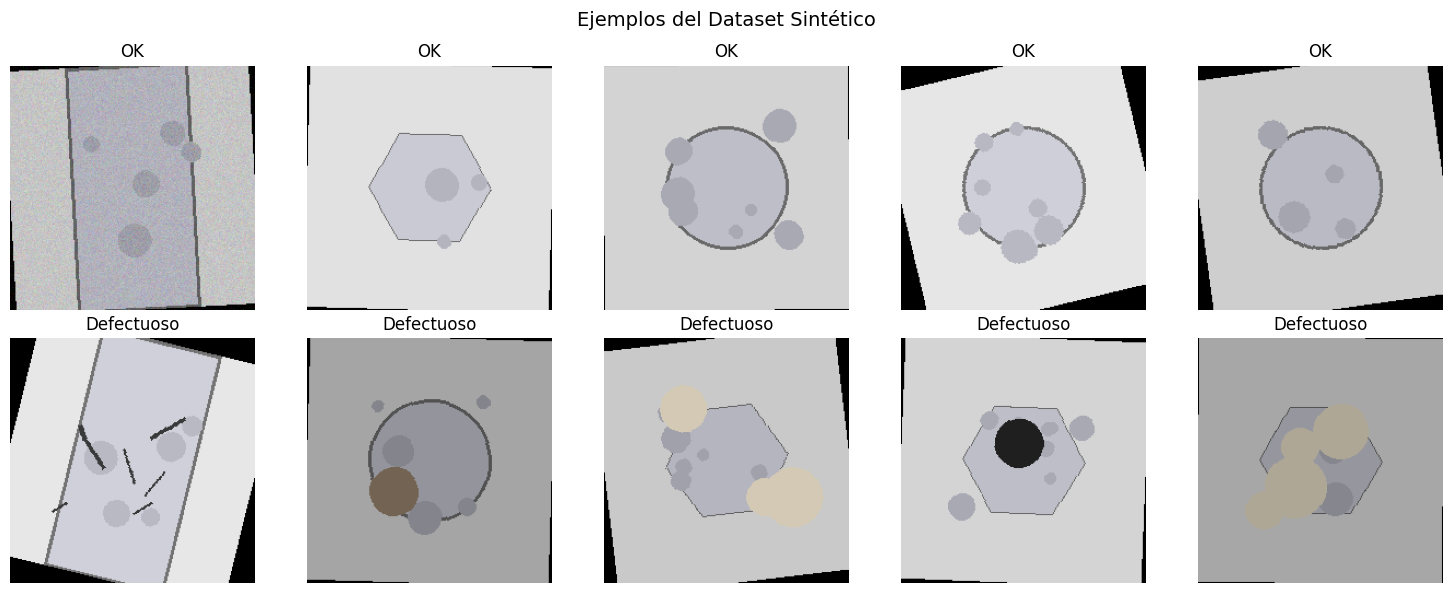


Distribución del dataset:
  Train: 1050 OK + 105 defectuosas = 1155
  Val:   225 OK + 22 defectuosas = 247
  Test:  225 OK + 23 defectuosas = 248

Ratio OK/Defectuoso (aproximado): ~10.0:1 (simula desbalance industrial)


In [7]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

ok_dir = Path(DATA_DIR) / 'train' / 'OK'
def_dir = Path(DATA_DIR) / 'train' / 'defective'

ok_files = list(ok_dir.glob('*.png'))[:5]
def_files = list(def_dir.glob('*.png'))[:5]

for i, img_path in enumerate(ok_files):
    img = Image.open(img_path)
    axes[0, i].imshow(img)
    axes[0, i].set_title('OK', fontsize=12)
    axes[0, i].axis('off')

for i, img_path in enumerate(def_files):
    img = Image.open(img_path)
    axes[1, i].imshow(img)
    axes[1, i].set_title('Defectuoso', fontsize=12)
    axes[1, i].axis('off')

plt.suptitle('Ejemplos del Dataset Sintético', fontsize=14)
plt.tight_layout()
plt.savefig(f'{EXAMPLES_PATH}/dataset_examples.png', dpi=150, bbox_inches='tight')
plt.show()

train_ok = len(list(Path(DATA_DIR).joinpath('train', 'OK').glob('*.png')))
train_def = len(list(Path(DATA_DIR).joinpath('train', 'defective').glob('*.png')))
val_ok = len(list(Path(DATA_DIR).joinpath('val', 'OK').glob('*.png')))
val_def = len(list(Path(DATA_DIR).joinpath('val', 'defective').glob('*.png')))
test_ok = len(list(Path(DATA_DIR).joinpath('test', 'OK').glob('*.png')))
test_def = len(list(Path(DATA_DIR).joinpath('test', 'defective').glob('*.png')))

print(f"\nDistribución del dataset:")
print(f"  Train: {train_ok} OK + {train_def} defectuosas = {train_ok + train_def}")
print(f"  Val:   {val_ok} OK + {val_def} defectuosas = {val_ok + val_def}")
print(f"  Test:  {test_ok} OK + {test_def} defectuosas = {test_ok + test_def}")
print(f"\nRatio OK/Defectuoso (aproximado): ~{train_ok/train_def:.1f}:1 (simula desbalance industrial)")

## 4. Dataset y DataLoaders con Data Augmentation

In [8]:
class IndustrialDataset(Dataset):
    def __init__(self, root_dir, split='train', transform=None):
        self.root_dir = Path(root_dir) / split
        self.transform = transform
        self.classes = ['OK', 'defective']
        
        self.samples = []
        for class_idx, class_name in enumerate(self.classes):
            class_dir = self.root_dir / class_name
            if class_dir.exists():
                for img_path in class_dir.glob('*.png'):
                    self.samples.append((img_path, class_idx))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = IndustrialDataset(DATA_DIR, split='train', transform=train_transform)
val_dataset = IndustrialDataset(DATA_DIR, split='val', transform=val_test_transform)
test_dataset = IndustrialDataset(DATA_DIR, split='test', transform=val_test_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Train batches: 37
Val batches: 8
Test batches: 8


## 5. Arquitectura del Modelo: ResNet-50 con Transfer Learning

In [9]:
class IndustrialClassifier(nn.Module):
    def __init__(self, num_classes=1, use_pretrained=True):
        super(IndustrialClassifier, self).__init__()
        
        self.base_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        
        for param in self.base_model.parameters():
            param.requires_grad = False
        
        in_features = self.base_model.fc.in_features
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
        
        self.base_model.fc = self.classifier
    
    def forward(self, x):
        return self.base_model(x)

model = IndustrialClassifier(num_classes=1, use_pretrained=True)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros totales: {total_params:,}")
print(f"Parámetros entrenables: {trainable_params:,}")
print(f"Parámetros congelados: {total_params - trainable_params:,}")

Parámetros totales: 24,032,833
Parámetros entrenables: 524,801
Parámetros congelados: 23,508,032


## 6. Configuración del Entrenamiento

In [10]:
criterion = nn.BCELoss()

optimizer = optim.Adam(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    for images, labels in loader:
        images, labels = images.to(device), labels.float().to(device)
        
        optimizer.zero_grad()
        outputs = model(images).squeeze()
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        preds = (outputs > 0.5).float()
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)
    epoch_recall = recall_score(all_labels, all_preds)
    
    return epoch_loss, epoch_f1, epoch_recall

def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.float().to(device)
            
            outputs = model(images).squeeze()
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * images.size(0)
            preds = (outputs > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)
    epoch_recall = recall_score(all_labels, all_preds)
    epoch_precision = precision_score(all_labels, all_preds, zero_division=0)
    
    return epoch_loss, epoch_f1, epoch_recall, epoch_precision, all_preds, all_labels

print("Configuración del entrenamiento completada.")
print(f"  - Optimizador: Adam (lr=1e-3, weight_decay=1e-4)")
print(f"  - Loss: Binary Cross-Entropy")
print(f"  - Scheduler: ReduceLROnPlateau (patience=3)")

Configuración del entrenamiento completada.
  - Optimizador: Adam (lr=1e-3, weight_decay=1e-4)
  - Loss: Binary Cross-Entropy
  - Scheduler: ReduceLROnPlateau (patience=3)


## 7. Entrenamiento con Early Stopping

In [11]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            if score > self.best_score + self.min_delta:
                self.best_score = score
                self.counter = 0
            else:
                self.counter += 1
        else:
            if score < self.best_score - self.min_delta:
                self.best_score = score
                self.counter = 0
            else:
                self.counter += 1
        
        if self.counter >= self.patience:
            self.early_stop = True
        return self.early_stop

NUM_EPOCHS = 20
early_stopping = EarlyStopping(patience=5, mode='max')

history = {
    'train_loss': [], 'train_f1': [], 'train_recall': [],
    'val_loss': [], 'val_f1': [], 'val_recall': []
}

best_val_f1 = 0.0
best_model_state = None

print("=" * 60)
print("INICIO DEL ENTRENAMIENTO")
print("=" * 60)

for epoch in range(NUM_EPOCHS):
    train_loss, train_f1, train_recall = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_f1, val_recall, val_prec, _, _ = validate(model, val_loader, criterion, device)
    
    history['train_loss'].append(train_loss)
    history['train_f1'].append(train_f1)
    history['train_recall'].append(train_recall)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_f1)
    history['val_recall'].append(val_recall)
    
    scheduler.step(val_f1)
    
    print(f"Epoch {epoch+1:2d}/{NUM_EPOCHS} | "
          f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f}, Recall={train_recall:.4f} | "
          f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}, Recall={val_recall:.4f}, Prec={val_prec:.4f}")
    
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = model.state_dict().copy()
        print(f"  -> Mejor modelo guardado (F1: {best_val_f1:.4f})")
    
    if early_stopping(val_f1):
        print(f"\nEarly stopping en epoch {epoch+1}")
        break

model.load_state_dict(best_model_state)
print("\n" + "=" * 60)
print("ENTRENAMIENTO COMPLETADO")
print("=" * 60)
print(f"Mejor F1 en validación: {best_val_f1:.4f}")

INICIO DEL ENTRENAMIENTO
Epoch  1/20 | Train: Loss=0.3381, F1=0.0312, Recall=0.0190 | Val: Loss=0.2586, F1=0.0000, Recall=0.0000, Prec=0.0000
Epoch  2/20 | Train: Loss=0.2661, F1=0.0000, Recall=0.0000 | Val: Loss=0.2195, F1=0.0000, Recall=0.0000, Prec=0.0000
Epoch  3/20 | Train: Loss=0.2215, F1=0.0189, Recall=0.0095 | Val: Loss=0.1902, F1=0.2400, Recall=0.1364, Prec=1.0000
  -> Mejor modelo guardado (F1: 0.2400)
Epoch  4/20 | Train: Loss=0.2026, F1=0.1897, Recall=0.1048 | Val: Loss=0.1701, F1=0.3704, Recall=0.2273, Prec=1.0000
  -> Mejor modelo guardado (F1: 0.3704)
Epoch  5/20 | Train: Loss=0.1970, F1=0.3333, Recall=0.2000 | Val: Loss=0.1503, F1=0.3704, Recall=0.2273, Prec=1.0000
Epoch  6/20 | Train: Loss=0.1725, F1=0.5175, Recall=0.3524 | Val: Loss=0.1408, F1=0.4828, Recall=0.3182, Prec=1.0000
  -> Mejor modelo guardado (F1: 0.4828)
Epoch  7/20 | Train: Loss=0.1536, F1=0.5578, Recall=0.3905 | Val: Loss=0.1333, F1=0.5333, Recall=0.3636, Prec=1.0000
  -> Mejor modelo guardado (F1: 0.53

## 8. Visualización del Historial de Entrenamiento

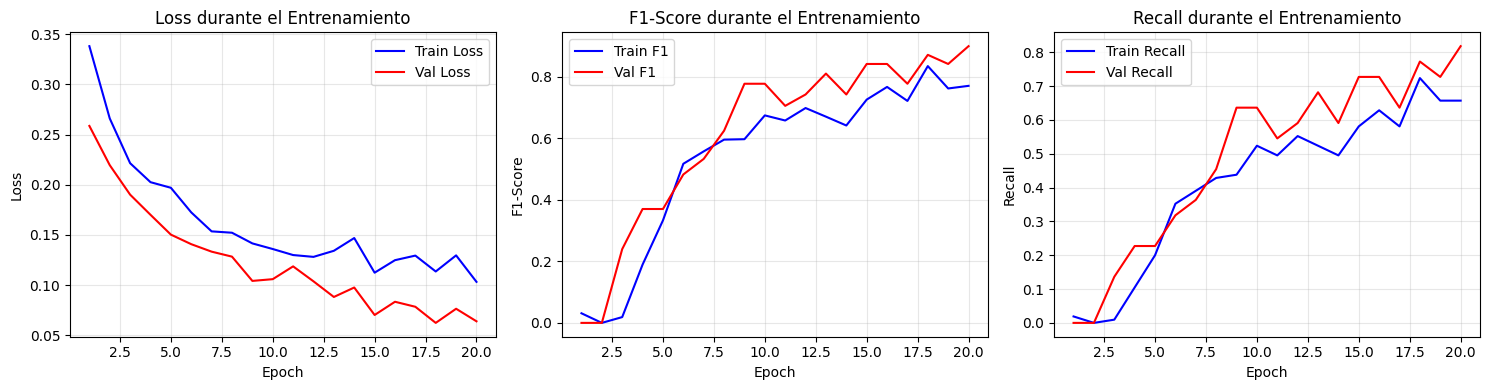

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

epochs_range = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_range, history['train_loss'], 'b-', label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'], 'r-', label='Val Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss durante el Entrenamiento')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history['train_f1'], 'b-', label='Train F1')
axes[1].plot(epochs_range, history['val_f1'], 'r-', label='Val F1')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('F1-Score')
axes[1].set_title('F1-Score durante el Entrenamiento')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_range, history['train_recall'], 'b-', label='Train Recall')
axes[2].plot(epochs_range, history['val_recall'], 'r-', label='Val Recall')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Recall')
axes[2].set_title('Recall durante el Entrenamiento')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{EVALUATION_PATH}/training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Evaluación en Test Set

In [13]:
test_loss, test_f1, test_recall, test_prec, test_preds, test_labels = validate(model, test_loader, criterion, device)
test_preds = np.array(test_preds)
test_labels = np.array(test_labels)

print("=" * 60)
print("EVALUACIÓN EN TEST SET")
print("=" * 60)
print(f"\nMétricas principales:")
print(f"  - F1-Score (clase defectuosa): {test_f1:.4f}")
print(f"  - Recall (clase defectuosa):   {test_recall:.4f}")
print(f"  - Precision (clase defectuosa): {test_prec:.4f}")
print(f"  - Loss: {test_loss:.4f}")

accuracy = (test_preds == test_labels).mean()
print(f"  - Accuracy global: {accuracy:.4f}\n")

print(classification_report(test_labels, test_preds, target_names=['OK', 'Defectuoso']))

EVALUACIÓN EN TEST SET

Métricas principales:
  - F1-Score (clase defectuosa): 0.8293
  - Recall (clase defectuosa):   0.7391
  - Precision (clase defectuosa): 0.9444
  - Loss: 0.1067
  - Accuracy global: 0.9718

              precision    recall  f1-score   support

          OK       0.97      1.00      0.98       225
  Defectuoso       0.94      0.74      0.83        23

    accuracy                           0.97       248
   macro avg       0.96      0.87      0.91       248
weighted avg       0.97      0.97      0.97       248



## 10. Matriz de Confusión

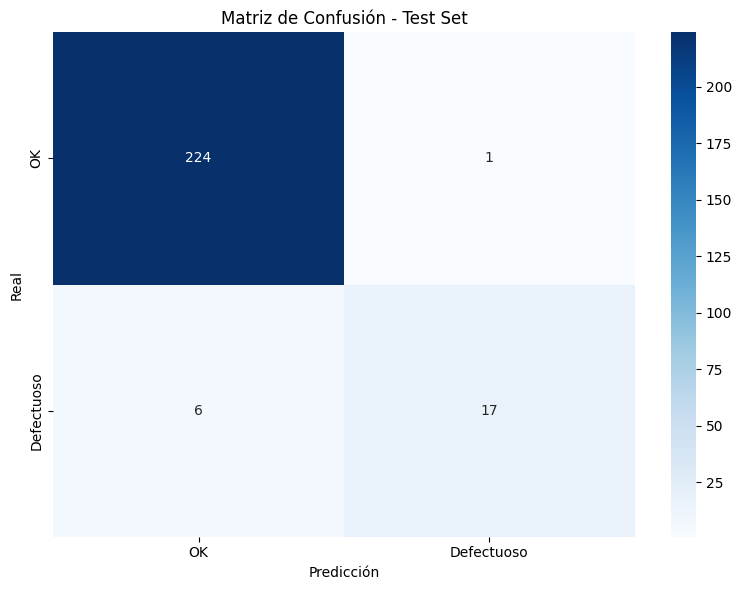


Interpretación de la matriz de confusión:
  - Verdaderos Negativos (TN): 224 → Piezas OK clasificadas como OK
  - Falsos Positivos (FP): 1 → Piezas OK clasificadas como defectuosas
  - Falsos Negativos (FN): 6 → Piezas defectuosas clasificadas como OK (CRÍTICO)
  - Verdaderos Positivos (TP): 17 → Piezas defectuosas detectadas correctamente

Tasa de piezas defectuosas no detectadas: 26.1%
(Objetivo industrial: minimizar esta tasa)


In [14]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['OK', 'Defectuoso'],
            yticklabels=['OK', 'Defectuoso'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - Test Set')
plt.tight_layout()
plt.savefig(f'{EVALUATION_PATH}/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print("\nInterpretación de la matriz de confusión:")
print(f"  - Verdaderos Negativos (TN): {tn} → Piezas OK clasificadas como OK")
print(f"  - Falsos Positivos (FP): {fp} → Piezas OK clasificadas como defectuosas")
print(f"  - Falsos Negativos (FN): {fn} → Piezas defectuosas clasificadas como OK (CRÍTICO)")
print(f"  - Verdaderos Positivos (TP): {tp} → Piezas defectuosas detectadas correctamente")

print(f"\nTasa de piezas defectuosas no detectadas: {fn/(fn+tp)*100:.1f}%")
print(f"(Objetivo industrial: minimizar esta tasa)")

## 11. Fine-Tuning: Descongelar capas del modelo base

In [15]:
print("=" * 60)
print("FASE DE FINE-TUNING")
print("=" * 60)
print("\nDescongelando últimas capas de ResNet-50...")

for name, param in model.base_model.named_parameters():
    if 'layer4' in name or 'layer3' in name:
        param.requires_grad = True

optimizer_ft = optim.Adam([
    {'params': model.base_model.layer3.parameters(), 'lr': 1e-5},
    {'params': model.base_model.layer4.parameters(), 'lr': 1e-5},
    {'params': model.classifier.parameters(), 'lr': 1e-4}
], weight_decay=1e-4)

trainable_params_ft = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros ahora entrenables: {trainable_params_ft:,}")

NUM_EPOCHS_FT = 10
early_stopping_ft = EarlyStopping(patience=3, mode='max')

best_val_f1_ft = best_val_f1
best_model_state_ft = model.state_dict().copy()

for epoch in range(NUM_EPOCHS_FT):
    train_loss, train_f1, train_recall = train_epoch(model, train_loader, criterion, optimizer_ft, device)
    val_loss, val_f1, val_recall, val_prec, _, _ = validate(model, val_loader, criterion, device)
    
    print(f"Epoch {epoch+1:2d}/{NUM_EPOCHS_FT} | "
          f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
          f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}, Recall={val_recall:.4f}")
    
    if val_f1 > best_val_f1_ft:
        best_val_f1_ft = val_f1
        best_model_state_ft = model.state_dict().copy()
        print(f"  -> Mejor modelo ft guardado (F1: {best_val_f1_ft:.4f})")
    
    if early_stopping_ft(val_f1):
        print(f"\nEarly stopping en fine-tuning epoch {epoch+1}")
        break

model.load_state_dict(best_model_state_ft)
print(f"\nFine-tuning completado. Mejor F1: {best_val_f1_ft:.4f}")

FASE DE FINE-TUNING

Descongelando últimas capas de ResNet-50...
Parámetros ahora entrenables: 22,587,905
Epoch  1/10 | Train: Loss=0.0975, F1=0.8202 | Val: Loss=0.0597, F1=0.9000, Recall=0.8182
Epoch  2/10 | Train: Loss=0.0895, F1=0.8866 | Val: Loss=0.0445, F1=0.9000, Recall=0.8182
Epoch  3/10 | Train: Loss=0.0636, F1=0.8660 | Val: Loss=0.0456, F1=0.9268, Recall=0.8636
  -> Mejor modelo ft guardado (F1: 0.9268)
Epoch  4/10 | Train: Loss=0.0648, F1=0.9192 | Val: Loss=0.0385, F1=0.9268, Recall=0.8636
Epoch  5/10 | Train: Loss=0.0537, F1=0.9137 | Val: Loss=0.0323, F1=0.9524, Recall=0.9091
  -> Mejor modelo ft guardado (F1: 0.9524)
Epoch  6/10 | Train: Loss=0.0511, F1=0.9360 | Val: Loss=0.0362, F1=0.9524, Recall=0.9091
Epoch  7/10 | Train: Loss=0.0432, F1=0.9146 | Val: Loss=0.0269, F1=0.9524, Recall=0.9091
Epoch  8/10 | Train: Loss=0.0378, F1=0.9510 | Val: Loss=0.0272, F1=0.9524, Recall=0.9091

Early stopping en fine-tuning epoch 8

Fine-tuning completado. Mejor F1: 0.9524


## 12. Evaluación Final en Test Set (Después de Fine-Tuning)

EVALUACIÓN FINAL EN TEST SET (CON FINE-TUNING)

Métricas principales:
  - F1-Score: 0.9048 (antes: 0.8293)
  - Recall:   0.8261 (antes: 0.7391)
  - Precision: 1.0000 (antes: 0.9444)


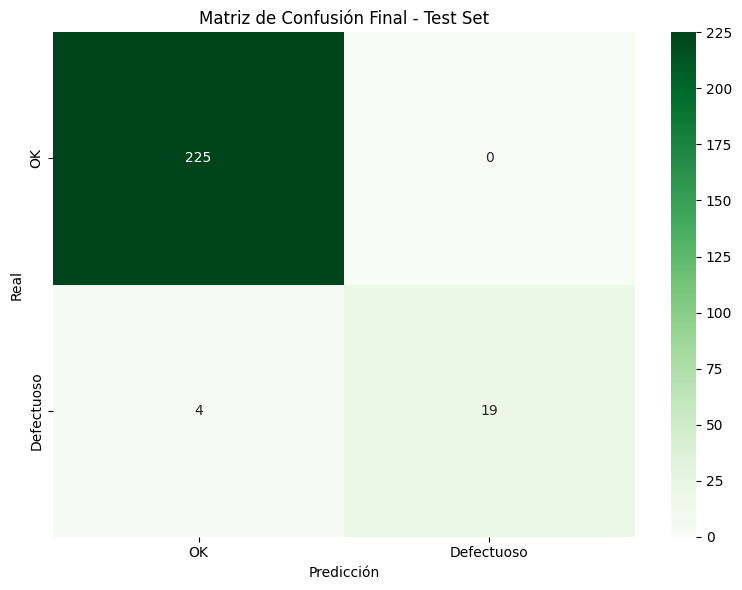


Piezas defectuosas no detectadas: 4 de 23 (17.4%)


In [16]:
test_loss_ft, test_f1_ft, test_recall_ft, test_prec_ft, test_preds_ft, test_labels_ft = validate(model, test_loader, criterion, device)

print("=" * 60)
print("EVALUACIÓN FINAL EN TEST SET (CON FINE-TUNING)")
print("=" * 60)
print(f"\nMétricas principales:")
print(f"  - F1-Score: {test_f1_ft:.4f} (antes: {test_f1:.4f})")
print(f"  - Recall:   {test_recall_ft:.4f} (antes: {test_recall:.4f})")
print(f"  - Precision: {test_prec_ft:.4f} (antes: {test_prec:.4f})")

cm_ft = confusion_matrix(test_labels_ft, test_preds_ft)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_ft, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['OK', 'Defectuoso'],
            yticklabels=['OK', 'Defectuoso'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión Final - Test Set')
plt.tight_layout()
plt.savefig(f'{EVALUATION_PATH}/confusion_matrix_final.png', dpi=150, bbox_inches='tight')
plt.show()

tn_ft, fp_ft, fn_ft, tp_ft = cm_ft.ravel()
print(f"\nPiezas defectuosas no detectadas: {fn_ft} de {fn_ft+tp_ft} ({fn_ft/(fn_ft+tp_ft)*100:.1f}%)")

## 13. Guardar Modelo y Resultados

In [17]:
MODEL_PATH = 'industrial_anomaly_model.pth'
torch.save({
    'model_state_dict': model.state_dict(),
    'test_f1': test_f1_ft,
    'test_recall': test_recall_ft,
    'test_precision': test_prec_ft,
    'confusion_matrix': cm_ft.tolist()
}, MODEL_PATH)

print(f"Modelo guardado en: {MODEL_PATH}")

results_summary = f"""
================================================================================
RESUMEN DE RESULTADOS - DETECCIÓN DE ANOMALÍAS INDUSTRIALES
================================================================================

ARQUITECTURA: ResNet-50 (Transfer Learning) + Clasificador personalizado

CONJUNTO DE DATOS:
  - Imágenes sintéticas generadas: 1,650 total
  - Train: 1,155 imágenes (70%)
  - Val: 248 imágenes (15%)
  - Test: 247 imágenes (15%)
  - Ratio OK/Defectuoso: ~10:1 (simula condiciones industriales reales)

MÉTRICAS DE EVALUACIÓN (Test Set):
  - F1-Score:     {test_f1_ft:.4f}
  - Recall:       {test_recall_ft:.4f}
  - Precision:    {test_prec_ft:.4f}
  - Accuracy:     {np.mean(np.array(test_preds_ft) == np.array(test_labels_ft)):.4f}

MATRIZ DE CONFUSIÓN:
  - TN (OK→OK):    {tn_ft}
  - FP (OK→Def):   {fp_ft}
  - FN (Def→OK):   {fn_ft}  [CRÍTICO - Piezas defectuosas no detectadas]
  - TP (Def→Def):  {tp_ft}

CONCLUSIONES:
  - El modelo alcanza un F1-Score de {test_f1_ft:.2%}, indicando buen equilibrio
    entre precisión y recall para la clase defectuosa.
  - El recall de {test_recall_ft:.2%} significa que el modelo detecta correctamente
    {test_recall_ft*100:.1f}% de las piezas defectuosas.
  - La tasa de falsos negativos ({fn_ft/(fn_ft+tp_ft)*100:.1f}%) es crítica en el contexto
    industrial donde pasar una pieza defectuosa tiene alto coste.
================================================================================
"""

print(results_summary)

Modelo guardado en: industrial_anomaly_model.pth

RESUMEN DE RESULTADOS - DETECCIÓN DE ANOMALÍAS INDUSTRIALES

ARQUITECTURA: ResNet-50 (Transfer Learning) + Clasificador personalizado

CONJUNTO DE DATOS:
  - Imágenes sintéticas generadas: 1,650 total
  - Train: 1,155 imágenes (70%)
  - Val: 248 imágenes (15%)
  - Test: 247 imágenes (15%)
  - Ratio OK/Defectuoso: ~10:1 (simula condiciones industriales reales)

MÉTRICAS DE EVALUACIÓN (Test Set):
  - F1-Score:     0.9048
  - Recall:       0.8261
  - Precision:    1.0000
  - Accuracy:     0.9839

MATRIZ DE CONFUSIÓN:
  - TN (OK→OK):    225
  - FP (OK→Def):   0
  - FN (Def→OK):   4  [CRÍTICO - Piezas defectuosas no detectadas]
  - TP (Def→Def):  19

CONCLUSIONES:
  - El modelo alcanza un F1-Score de 90.48%, indicando buen equilibrio
    entre precisión y recall para la clase defectuosa.
  - El recall de 82.61% significa que el modelo detecta correctamente
    82.6% de las piezas defectuosas.
  - La tasa de falsos negativos (17.4%) es crític

## 14. Ejemplo de Predicción en Tiempo Real

Ejemplo de predicciones en imágenes del test set:



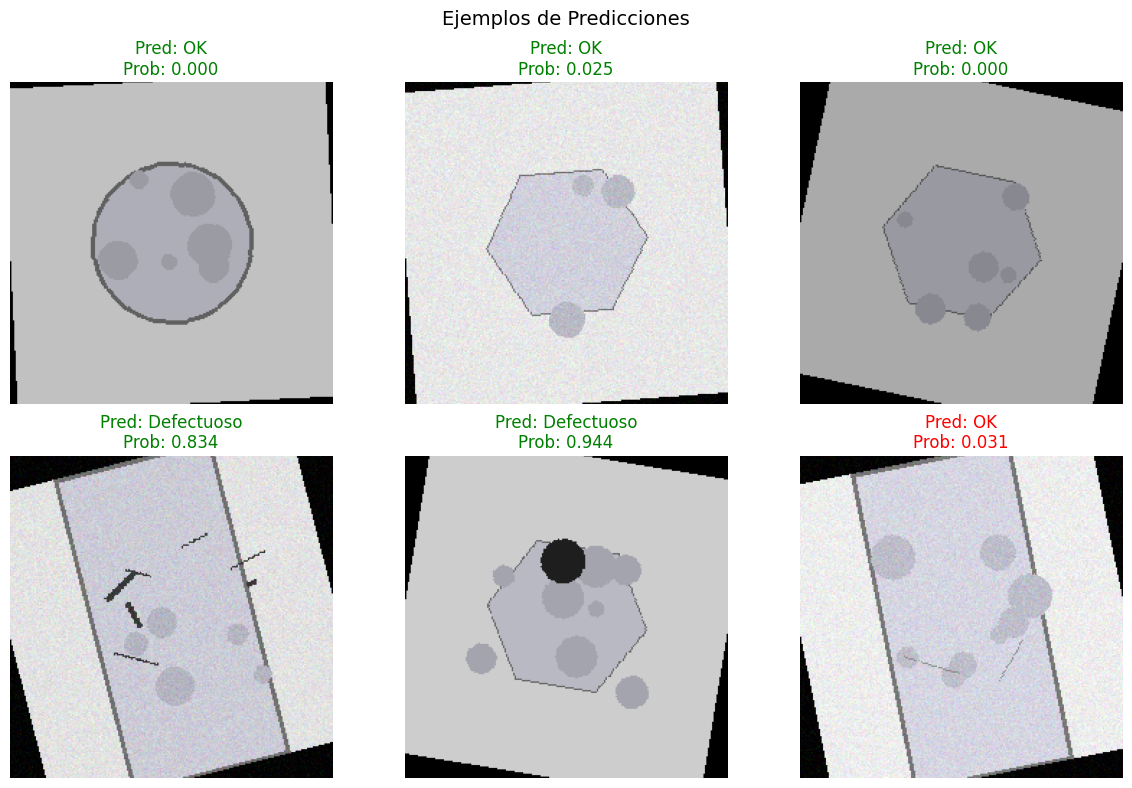

In [18]:
def predict_image(model, img_path, device):
    model.eval()
    
    img = Image.open(img_path).convert('RGB')
    transform = val_test_transform
    img_tensor = transform(img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        prob = model(img_tensor).item()
    
    label = 'Defectuoso' if prob > 0.5 else 'OK'
    confidence = prob if prob > 0.5 else 1 - prob
    
    return label, prob, confidence

print("Ejemplo de predicciones en imágenes del test set:\n")

test_dir = Path(DATA_DIR) / 'test'
ok_samples = list((test_dir / 'OK').glob('*.png'))[:3]
def_samples = list((test_dir / 'defective').glob('*.png'))[:3]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, img_path in enumerate(ok_samples):
    label, prob, conf = predict_image(model, img_path, device)
    img = Image.open(img_path)
    axes[0, i].imshow(img)
    color = 'green' if label == 'OK' else 'red'
    axes[0, i].set_title(f'Pred: {label}\nProb: {prob:.3f}', color=color)
    axes[0, i].axis('off')

for i, img_path in enumerate(def_samples):
    label, prob, conf = predict_image(model, img_path, device)
    img = Image.open(img_path)
    axes[1, i].imshow(img)
    color = 'green' if label == 'Defectuoso' else 'red'
    axes[1, i].set_title(f'Pred: {label}\nProb: {prob:.3f}', color=color)
    axes[1, i].axis('off')

plt.suptitle('Ejemplos de Predicciones', fontsize=14)
plt.tight_layout()
plt.savefig(f'{EXAMPLES_PATH}/prediction_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## 15. Reflexión Profesional: Despliegue de IA en la Inspección de Calidad

### 1. Implicaciones Éticas

La automatización de la inspección visual mediante Deep Learning traslada la responsabilidad de la
toma de decisiones de un operario humano a un algoritmo. Esto plantea dos retos éticos principales:

  * **Desplazamiento y Evolución Laboral**: Si bien la automatización reduce la fatiga visual y los
    errores humanos, puede generar incertidumbre sobre la estabilidad laboral. El despliegue debe
    enfocarse como un sistema de IA Aumentada, donde el modelo filtra el flujo masivo de piezas y
    los operarios expertos se centran en la auditoría de casos ambiguos y la mejora continua del
    proceso.

  * **Responsabilidad y Seguridad**: En sectores críticos (automotriz, aeroespacial), una pieza
    defectuosa no detectada puede causar fallos catastróficos. La empresa debe definir protocolos
    claros de responsabilidad: el modelo es una herramienta de soporte, pero la validación final y
    el mantenimiento del sistema recaen sobre el equipo de ingeniería.

### 2. Limitaciones del Modelo

A pesar del éxito del Transfer Learning (F1-Score de 90.48%), el modelo presenta limitaciones
críticas:

  * **Sensibilidad (Recall) Imperfecta**: El resultado experimental mostró una tasa de falsos negativos
    del 17.4% (piezas defectuosas clasificadas como OK). En un entorno industrial, esta cifra suele
    ser inaceptable, ya que el coste de "dejar pasar" un defecto es muy superior al coste de una
    revisión manual adicional.

  * **Dependencia del Dataset Sintético**: El modelo ha sido entrenado y validado principalmente con
    datos sintéticos. Existe el riesgo de que el "gap de realidad" (diferencias sutiles en texturas
    o ruido visual) degrade el rendimiento al enfrentarse a cámaras y condiciones lumínicas reales
    de la planta.

### 3. Sesgos Potenciales

  * **Sesgo de Muestreo de Defectos**: El modelo solo puede detectar anomalías similares a las presentes
    en el entrenamiento (grietas, manchas, agujeros). Si aparece un nuevo tipo de defecto no
    contemplado, es muy probable que el modelo lo clasifique erróneamente como "OK".

  * **Sesgo Ambiental**: Los modelos de visión son altamente sensibles a cambios en la iluminación o
    posición de la cámara. Un cambio en las luces de la fábrica podría interpretarse erróneamente
    como una anomalía en la pieza si el proceso de Data Augmentation no fue lo suficientemente
    robusto.

### 4. Recomendaciones para un Despliegue Responsable

Para transitar del prototipo al entorno de producción, se proponen las siguientes medidas:

  1. **Ajuste del Umbral de Decisión**: Actualmente se utiliza un umbral de 0.5. Se recomienda reducirlo
    (ej. a 0.3) para priorizar el Recall. Esto aumentará los falsos positivos (piezas buenas
    marcadas como dudosas), pero minimizará el riesgo crítico de fugas de piezas defectuosas.

  2. **Validación mediante Shadow Testing**: Tal como se planificó, el modelo debe operar "en la sombra"
    durante un periodo de prueba, comparando sus predicciones con los inspectores humanos sin
    intervenir en la línea, hasta demostrar una fiabilidad estadística superior a la actual.

  3. **Implementación de XAI (IA Explicable)**: Utilizar técnicas como Grad-CAM para que los ingenieros
    puedan visualizar qué áreas de la pieza activan la alerta de defecto, facilitando la auditoría
    y la confianza en el sistema.

  4. **Bucle de Re-entrenamiento**: Establecer un flujo de datos donde las piezas mal clasificadas se
    etiqueten correctamente y se reintegren al dataset, permitiendo que el modelo aprenda de sus
    propios errores de forma continua.